# Task 3 – K-Nearest Neighbors on `diabetes.csv`
Compute: confusion matrix, accuracy, error rate, precision and recall.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report, ConfusionMatrixDisplay)
import warnings; warnings.filterwarnings("ignore")

df = pd.read_csv("diabetes.csv")
print("Shape:", df.shape)
df.head()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nClass balance:\n", df["Outcome"].value_counts())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values:
 Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

Class balance:
 Outcome
0    500
1    268
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
Pedigree,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


## 1. Pre-processing
In this dataset a **0** in `Glucose, BloodPressure, SkinThickness, Insulin, BMI` is physically impossible – it really means *missing*. We replace those zeros with the column median.

In [3]:
cols_with_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Zeros before:\n", (df[cols_with_zero] == 0).sum())
df[cols_with_zero] = df[cols_with_zero].replace(0, np.nan)
df[cols_with_zero] = df[cols_with_zero].fillna(df[cols_with_zero].median())
print("\nZeros after:\n", (df[cols_with_zero] == 0).sum())

Zeros before:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Zeros after:
 Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


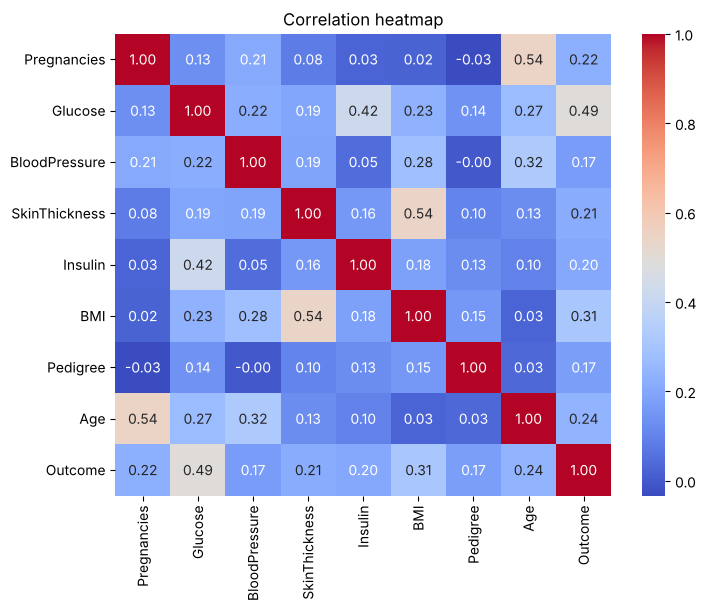

In [4]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap"); plt.show()

## 2. Train / test split and scaling
KNN is distance-based, so features **must** be scaled. The scaler is fit on the training set only (no data leakage).

In [5]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
print(X_train_s.shape, X_test_s.shape)

(614, 8) (154, 8)


## 3. Choosing K
We try K = 1…30 and look at the error rate.

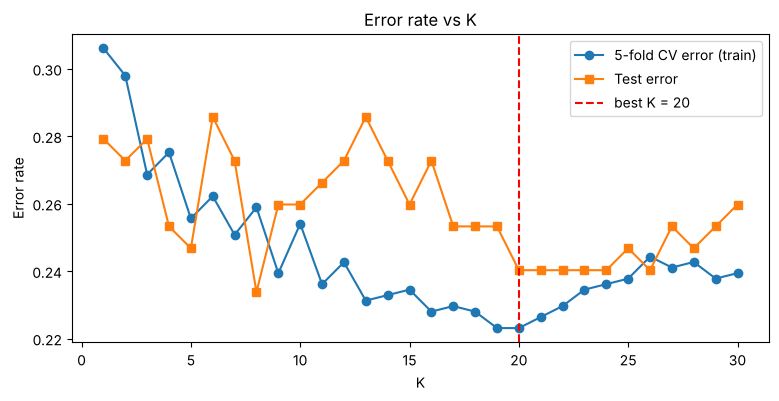

Best K (lowest cross-validated error): 20


In [6]:
from sklearn.model_selection import cross_val_score
ks = range(1, 31)
cv_err, test_err = [], []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    cv_err.append(1 - cross_val_score(knn, X_train_s, y_train, cv=5).mean())
    test_err.append(1 - knn.fit(X_train_s, y_train).score(X_test_s, y_test))

best_k = ks[int(np.argmin(cv_err))]
plt.figure(figsize=(9,4))
plt.plot(ks, cv_err, marker="o", label="5-fold CV error (train)")
plt.plot(ks, test_err, marker="s", label="Test error")
plt.axvline(best_k, color="r", ls="--", label=f"best K = {best_k}")
plt.xlabel("K"); plt.ylabel("Error rate"); plt.legend(); plt.title("Error rate vs K"); plt.show()
print("Best K (lowest cross-validated error):", best_k)

## 4. Final model and metrics

In [7]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_s, y_train)
y_pred = knn.predict(X_test_s)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
acc  = accuracy_score(y_test, y_pred)

print("Confusion matrix:\n", cm)
print(f"\nTN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"\nAccuracy   : {acc:.4f}")
print(f"Error rate : {1-acc:.4f}")
print(f"Precision  : {precision_score(y_test, y_pred):.4f}")
print(f"Recall     : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score   : {f1_score(y_test, y_pred):.4f}")

Confusion matrix:
 [[87 13]
 [24 30]]

TN=87  FP=13  FN=24  TP=30

Accuracy   : 0.7597
Error rate : 0.2403
Precision  : 0.6977
Recall     : 0.5556
F1-score   : 0.6186


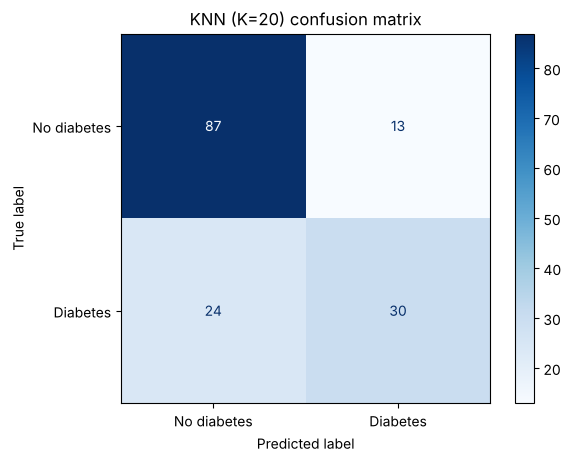

              precision    recall  f1-score   support

 No diabetes       0.78      0.87      0.82       100
    Diabetes       0.70      0.56      0.62        54

    accuracy                           0.76       154
   macro avg       0.74      0.71      0.72       154
weighted avg       0.75      0.76      0.75       154



In [8]:
ConfusionMatrixDisplay(cm, display_labels=["No diabetes","Diabetes"]).plot(cmap="Blues")
plt.title(f"KNN (K={best_k}) confusion matrix"); plt.show()
print(classification_report(y_test, y_pred, target_names=["No diabetes","Diabetes"]))

## Conclusion
- Accuracy ≈ shown above; error rate = 1 − accuracy.
- **Precision** = of the patients predicted diabetic, how many truly are. **Recall** = of the truly diabetic patients, how many we caught.
- Recall on the diabetic class is the weaker number, because the data is imbalanced (500 vs 268). In medical screening a false negative is costlier than a false positive, so recall matters most.